# Experiment 2 tree metrics and Test 2 comparison(ESTE)

This notebook extends an **existing** neighborhood-audit run. It reads its saved per-flow
Parquet files and manifest, reconstructs the same three histogram gradient-boosted tree
models, and checks validation/Test 2 AP against `conditional_baseline_ap.csv`.
It does not rerun graph construction, the neighborhood audit, or neural-network training.
The original audit saved AP tables but did not persist its fitted trees; the first execution
here therefore refits those trees. Successful model files are cached for subsequent runs.

For each tree, select a maximum-F1 threshold on the **full Wednesday validation split**,
freeze it, then compute Test 2 F1, FPR, and unique attacked sources with at least one
true-positive flow. Test 2 labels never select thresholds. The decision operator is `>`.
Predictions are joined to the factorial experiment's flow index by window and edge key,
and labels and endpoint IDs must agree. The Test 2 comparison uses original labels.

Run baseline_retraining_factorial_protocol_colab.ipynb first for the final comparison.
The figure defaults to six factorial champions, four newly retrained baselines
(MLP, Static GNN, Edge GRU, E-GraphSAGE), historical ST-GNN, and three tree baselines.
Select BASELINE_SOURCE=historical in the plotting cell to use the earlier baselines. Circle **area**, rather than diameter, is
proportional to the number of detected attack sources. Numbered circles match the legend.
All neural-model thresholds remain at their saved validation values.

The tree baselines use one seed and the audit's training sample of at most 500,000 rows.
Their endpoint/neighborhood context follows the audit manifest and may differ in time
availability and observation horizon from the retrospective GNN inputs. Treat them as
external diagnostic baselines, rather than additional cells of the controlled factorial.
Run in Colab on CPU. No local tests or notebook cells were executed during authoring.

In [ ]:
import importlib.util
import subprocess
import sys
from pathlib import Path

if importlib.util.find_spec('pyarrow') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyarrow'], check=True)

from google.colab import drive
drive.mount('/content/drive')

import gc
import hashlib
import json
import platform
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve

ROOT = Path('/content/drive/MyDrive/nids-mitre')
# Select the exact existing Experiment 2 run; do not select a run by test performance.
AUDIT_RUN = ROOT / 'results_comparison/graph_neighborhood_audit_v1/run_20261022T142050Z'
FACTORIAL_DIR = ROOT / 'results_stgnn_memory_message_factorial_v1'
HISTORICAL_DIR = ROOT / 'results_comparison/temporal_operational_v1'
METRIC_VERSION = 'tree_operating_points_v1'
TREE_OUTPUT = AUDIT_RUN / METRIC_VERSION
TREE_OUTPUT.mkdir(parents=True, exist_ok=True)

required = [AUDIT_RUN / 'manifest.json', AUDIT_RUN / 'conditional_baseline_ap.csv',
            AUDIT_RUN / 'per_flow/wed', AUDIT_RUN / 'per_flow/thu',
            FACTORIAL_DIR / 'alignment/test2_flows.parquet',
            FACTORIAL_DIR / 'test2_champions.csv',
            HISTORICAL_DIR / 'flow_metrics_baselines.csv',
            HISTORICAL_DIR / 'source_temporal_summary.csv']
for path in required:
    assert path.exists(), f'Missing required artifact: {path}'

audit_manifest = json.loads((AUDIT_RUN / 'manifest.json').read_text())
TREE_FEATURES = audit_manifest['baseline_feature_sets']
tree_configuration = dict(audit_manifest['baseline_configuration'])
assert tree_configuration.pop('model') == 'HistGradientBoostingClassifier'
MAX_TRAIN_ROWS = int(tree_configuration.pop('max_train_rows'))
TREE_SEED = int(tree_configuration['random_state'])
CONTEXT = audit_manifest['baseline_context']
ALL_FEATURES = list(dict.fromkeys(c for features in TREE_FEATURES.values() for c in features))
assert not any(c.startswith('diag_') or c in {
    'label', 'source_gid', 'destination_gid', 'attack_age_windows'
} for c in ALL_FEATURES)

TREE_LABELS = {
    'target_only': 'HGB: flow only',
    'target_plus_endpoint_history': 'HGB: flow + endpoints',
    'target_endpoint_plus_neighbors': 'HGB: flow + endpoints + neighbors',
}
assert set(TREE_FEATURES) == set(TREE_LABELS)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

provenance = dict(
    audit_manifest_sha256=file_sha256(AUDIT_RUN / 'manifest.json'),
    reference_ap_sha256=file_sha256(AUDIT_RUN / 'conditional_baseline_ap.csv'),
    feature_sets=TREE_FEATURES, configuration=tree_configuration,
    max_train_rows=MAX_TRAIN_ROWS, context=CONTEXT,
    threshold_policy='full_validation_max_F1; strict_probability_gt_threshold',
    python=platform.python_version(), sklearn=sklearn.__version__,
    numpy=np.__version__, pandas=pd.__version__,
)
provenance_path = TREE_OUTPUT / 'provenance.json'
if provenance_path.exists():
    assert json.loads(provenance_path.read_text()) == provenance, (
        'Inputs, configuration, or software changed. Use a new METRIC_VERSION.')
else:
    provenance_path.write_text(json.dumps(provenance, indent=2))

print('Audit run:', AUDIT_RUN)
print('Context:', CONTEXT)
print('Output:', TREE_OUTPUT)

Mounted at /content/drive
Audit run: /content/drive/MyDrive/nids-mitre/results_comparison/graph_neighborhood_audit_v1/run_20261022T142050Z
Context: causal_prior_completed
Output: /content/drive/MyDrive/nids-mitre/results_comparison/graph_neighborhood_audit_v1/run_20261022T142050Z/tree_operating_points_v1


## 1. Reconstruct the original training sample and align Test 2

Sampling preserves the exact original logic and file order. Source IDs and stable edge
keys are loaded for evaluation only; they are excluded from the feature sets. A positive
source means a source with at least one attack-labeled Test 2 flow. A detected source
must have at least one such flow exceeding the validation-selected threshold.

In [ ]:
FLOW_KEYS = ['window_id', 'edge_index_within_graph', 'source_gid', 'destination_gid']

def load_tree_split(day, split, include_keys=False):
    columns = ['split', 'label', *ALL_FEATURES]
    if include_keys:
        columns += FLOW_KEYS
    frames = []
    paths = sorted((AUDIT_RUN / 'per_flow' / day).glob('part_*.parquet'))
    assert paths, f'No per-flow files for {day}'
    for path in paths:
        part = pd.read_parquet(path, columns=columns)
        selected = part.loc[part['split'].eq(split)]
        if len(selected):
            frames.append(selected)
    assert frames, f'Empty partition: {day}/{split}'
    result = pd.concat(frames, ignore_index=True)
    assert result['label'].isin([0, 1]).all()
    return result

tree_train = load_tree_split('wed', 'train')
# Use the original seed and original sampling order, including the no-sampling case.
if len(tree_train) > MAX_TRAIN_ROWS:
    rng = np.random.default_rng(TREE_SEED)
    positive = np.flatnonzero(tree_train['label'].to_numpy() == 1)
    negative = np.flatnonzero(tree_train['label'].to_numpy() == 0)
    keep_positive = min(len(positive), MAX_TRAIN_ROWS // 2)
    selected = np.concatenate([
        rng.choice(positive, keep_positive, replace=False),
        rng.choice(negative, MAX_TRAIN_ROWS - keep_positive, replace=False),
    ])
    tree_fit = tree_train.iloc[np.sort(selected)].reset_index(drop=True)
    del tree_train
else:
    tree_fit = tree_train
    del tree_train
gc.collect()

tree_validation = load_tree_split('wed', 'val')
tree_test = load_tree_split('thu', 'test2', include_keys=True)
assert not tree_test.duplicated(['window_id', 'edge_index_within_graph']).any()

reference_index = pd.read_parquet(FACTORIAL_DIR / 'alignment/test2_flows.parquet')
assert reference_index['flow_index'].is_unique
actual = tree_test.rename(columns={'edge_index_within_graph': 'edge_index_in_graph'})
comparison_columns = ['window_id', 'edge_index_in_graph', 'source_gid', 'destination_gid', 'label']
actual = actual.sort_values(['window_id', 'edge_index_in_graph']).reset_index(drop=True)
expected = reference_index.sort_values(['window_id', 'edge_index_in_graph']).reset_index(drop=True)
for column in comparison_columns:
    assert np.array_equal(actual[column].to_numpy(), expected[column].to_numpy()), (
        f'Tree/GNN flow alignment mismatch: {column}')

# Record the join to the original graph order in saved prediction files.
flow_map = reference_index.set_index(['window_id', 'edge_index_in_graph'])['flow_index']
test_keys = pd.MultiIndex.from_frame(tree_test[['window_id', 'edge_index_within_graph']])
tree_flow_index = flow_map.reindex(test_keys).to_numpy()
assert np.isfinite(tree_flow_index).all() and len(np.unique(tree_flow_index)) == len(tree_test)
tree_flow_index = tree_flow_index.astype(np.int64)
assert len(tree_test) == 2_135_957 and int(tree_test['label'].sum()) == 103_825

del actual, expected, reference_index, flow_map
gc.collect()
print('Fit sample:', len(tree_fit), '| positive:', int(tree_fit['label'].sum()))
print('Validation:', len(tree_validation), '| Test 2:', len(tree_test))

Fit sample: 500000 | positive: 49564
Validation: 788535 | Test 2: 2135957


## 2. Validation thresholds and Test 2 operating metrics

The precision-recall curve describes predictions with `score >= threshold`. Moving the
selected threshold down by one representable float implements the same decision set with
our strict `score > threshold` operator, including tied tree probabilities. Check the
selected F1 directly on validation. AP must reproduce the existing audit within a small
numerical tolerance before new operating metrics are accepted. On mismatch, inspect the
training environment and feature artifacts; the historical CSV is never overwritten.

In [ ]:
reference_ap = pd.read_csv(AUDIT_RUN / 'conditional_baseline_ap.csv')

def check_reference_ap(feature_set, split, labels, probabilities):
    rows = reference_ap.loc[
        reference_ap['model'].eq(feature_set) & reference_ap['split'].eq(split)]
    assert len(rows) == 1, (feature_set, split)
    row = rows.iloc[0]
    assert int(row['flows']) == len(labels) and int(row['positives']) == int(labels.sum())
    measured = float(average_precision_score(labels, probabilities))
    assert np.isclose(measured, float(row['AP']), atol=1e-6, rtol=1e-5), (
        f'{feature_set}/{split}: AP {measured:.8f} does not reproduce '
        f'{float(row["AP"]):.8f}. Check scikit-learn versions and original artifacts.')
    return measured

def strict_max_f1_threshold(labels, probabilities):
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-10)
    best = int(np.argmax(f1))
    threshold = float(np.nextafter(float(thresholds[best]), -np.inf))
    predictions = probabilities > threshold
    tp = int(np.sum(predictions & (labels == 1)))
    fp = int(np.sum(predictions & (labels == 0)))
    fn = int(np.sum(~predictions & (labels == 1)))
    measured_f1 = 2 * tp / (2 * tp + fp + fn)
    assert np.isclose(measured_f1, f1[best], atol=1e-8)
    return threshold, measured_f1

tree_metric_rows = []
y_val = tree_validation['label'].to_numpy(dtype=np.int8)
y_test = tree_test['label'].to_numpy(dtype=np.int8)
test_sources = tree_test['source_gid'].to_numpy(dtype=np.int64)
n_attack_sources = int(np.unique(test_sources[y_test == 1]).size)
assert n_attack_sources == 380

for feature_set, features in TREE_FEATURES.items():
    model_path = TREE_OUTPUT / f'{feature_set}.joblib'
    if model_path.exists():
        tree_model = joblib.load(model_path)
        assert tree_model.get_params() == HistGradientBoostingClassifier(**tree_configuration).get_params()
        print(feature_set, ': reusing saved fitted tree')
    else:
        print(feature_set, ': fitting original tree configuration')
        tree_model = HistGradientBoostingClassifier(**tree_configuration)
        tree_model.fit(tree_fit[features].to_numpy(dtype=np.float32),
                       tree_fit['label'].to_numpy())

    val_scores = tree_model.predict_proba(tree_validation[features].to_numpy(dtype=np.float32))[:, 1]
    val_ap = check_reference_ap(feature_set, 'validation', y_val, val_scores)
    threshold, val_f1 = strict_max_f1_threshold(y_val, val_scores)
    test_scores = tree_model.predict_proba(tree_test[features].to_numpy(dtype=np.float32))[:, 1]
    test_ap = check_reference_ap(feature_set, 'test2', y_test, test_scores)
    assert np.isfinite(test_scores).all()
    predictions = test_scores > threshold
    tn, fp, fn, tp = map(int, confusion_matrix(y_test, predictions, labels=[0, 1]).ravel())
    detected_sources = int(np.unique(test_sources[predictions & (y_test == 1)]).size)
    row = dict(
        model=TREE_LABELS[feature_set], feature_set=feature_set,
        split='test2', seed=TREE_SEED, context_type=CONTEXT,
        flows=len(y_test), attacks=int(y_test.sum()), prevalence=float(y_test.mean()),
        fit_rows=len(tree_fit), fit_positive_rows=int(tree_fit['label'].sum()),
        threshold=threshold, validation_AP=val_ap, validation_F1=val_f1,
        F1=2 * tp / (2 * tp + fp + fn), FPR=fp / (fp + tn),
        Precision=tp / (tp + fp) if tp + fp else 0.0,
        Recall=tp / (tp + fn), **{'AUC-PR': test_ap},
        TP=tp, FP=fp, TN=tn, FN=fn,
        sources_detected=detected_sources, attacked_sources=n_attack_sources,
        source_detection_fraction=detected_sources / n_attack_sources,
        status='complete',
    )
    joblib.dump(tree_model, model_path)
    row['model_sha256'] = file_sha256(model_path)
    np.savez_compressed(
        TREE_OUTPUT / f'{feature_set}_test2_scores.npz',
        flow_index=tree_flow_index, probabilities=test_scores,
        threshold=np.array(threshold), model_sha256=np.array(row['model_sha256']),
        alignment_sha256=np.array(file_sha256(FACTORIAL_DIR / 'alignment/test2_flows.parquet')),
    )
    tree_metric_rows.append(row)
    tree_metrics = pd.DataFrame(tree_metric_rows)
    tree_metrics.to_csv(TREE_OUTPUT / 'tree_test2_operating_metrics.csv', index=False)
    print(f'  AP={test_ap:.4f} | F1={row["F1"]:.4f} | FPR={row["FPR"]:.4f} | '
          f'sources={detected_sources}/{n_attack_sources}')
    del tree_model, val_scores, test_scores
    gc.collect()

display(tree_metrics[['model', 'context_type', 'threshold', 'AUC-PR', 'F1', 'FPR',
                      'sources_detected', 'attacked_sources', 'FP']].round(5))

target_only : fitting original tree configuration
  AP=0.4617 | F1=0.4384 | FPR=0.0166 | sources=12/380
target_plus_endpoint_history : fitting original tree configuration
  AP=0.1920 | F1=0.1658 | FPR=0.0043 | sources=7/380
target_endpoint_plus_neighbors : fitting original tree configuration
  AP=0.3293 | F1=0.3291 | FPR=0.0288 | sources=17/380


,model,context_type,threshold,AUC-PR,F1,FPR,sources_detected,attacked_sources,FP
0,HGB: flow only,causal_prior_completed,0.32155,0.46172,0.43838,0.01660,12,380,33741
1,HGB: flow + endpoints,causal_prior_completed,0.67859,0.19196,0.16584,0.00425,7,380,8643
2,HGB: flow + endpoints + neighbors,causal_prior_completed,0.30704,0.32934,0.32906,0.02877,17,380,58473


## 3. Add all three tree baselines to the bubble chart

The numbered legend gives the model, seed, and detected-source count. Circle area encodes
source count, the x-axis is FPR in percent, and the y-axis is F1. The preferred region is
the upper left. Each point retains its own validation-selected threshold; the figure does
not equalize alert budgets or FPR. Historical ST-GNN and M1_P1 are separate trained runs
of the same architecture. Set `FPR_SCALE='symlog'` if large tree FPR values compress the
other points; the linear portion then covers 0 to 0.1 percentage points.

This cell can also run in a later Colab session after the setup cell: it reads all metrics
from Drive and performs no training. Output files go under the selected audit run's
`tree_operating_points_v1` directory, leaving previous figures and neural checkpoints intact.

The default BASELINE_SOURCE is retrained. Finish the baseline-retraining notebook
before running the plot. Tree metric computation is independent of baseline training.
The historical mode remains available explicitly, and output filenames identify the mode.


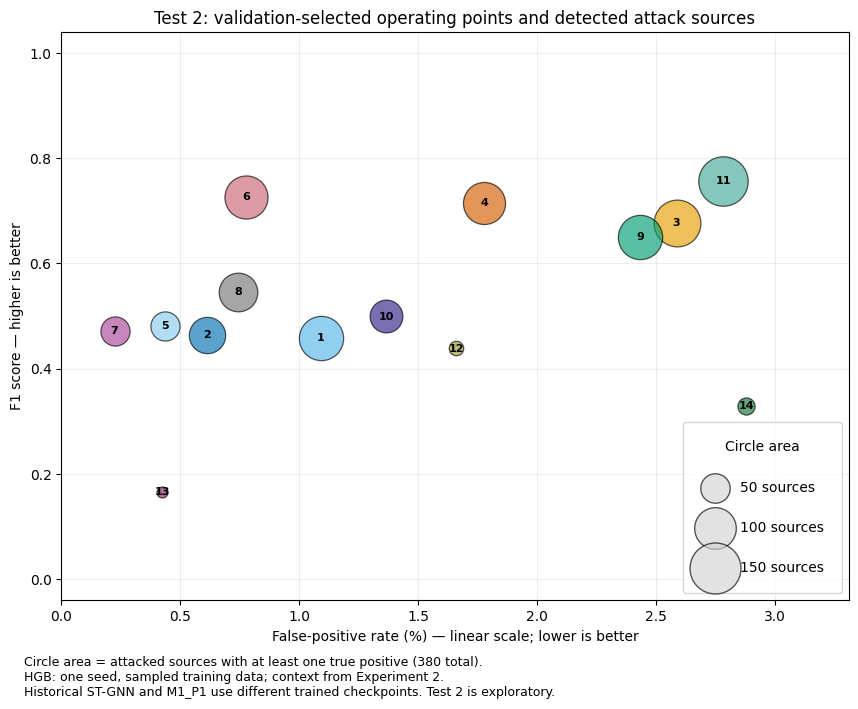

,model,seed,F1,FPR,sources_detected,attacked_sources,FPR_percent,plot_id
0,M0_P0,2024,0.4585,0.01089,113,380,1.089,1
1,M0_P1,123,0.4639,0.00610,76,380,0.610,2
2,M1_P0,2024,0.6775,0.02586,126,380,2.586,3
3,M1_P1,2024,0.7157,0.01776,102,380,1.776,4
4,M0_P0_param,2024,0.4809,0.00438,49,380,0.438,5
5,M1_P0_param,2024,0.7265,0.00778,107,380,0.778,6
6,MLP (retrained),777,0.4722,0.00224,49,380,0.224,7
7,Static GNN (retrained),99,0.5453,0.00744,86,380,0.744,8
8,Edge GRU (retrained),99,0.6502,0.02431,113,380,2.431,9
9,E-GraphSAGE (retrained),2024,0.4993,0.01365,62,380,1.365,10


Saved metrics and figures: /content/drive/MyDrive/nids-mitre/results_comparison/graph_neighborhood_audit_v1/run_20261022T142050Z/tree_operating_points_v1


In [ ]:
BASELINE_SOURCE = 'retrained'  # Alternatively: 'historical'.
FPR_SCALE = 'linear'  # Alternatively: 'symlog'.
AREA_PER_SOURCE = 9.0
columns = ['model', 'seed', 'F1', 'FPR', 'sources_detected', 'attacked_sources']

factorial = pd.read_csv(FACTORIAL_DIR / 'test2_champions.csv')
factorial = factorial.loc[factorial['status'].eq('complete'), columns].copy()

historical_names = {
    'Simple MLP': 'MLP', 'Static GNN': 'Static GNN',
    'ST-GNN': 'ST-GNN (original)', 'Edge GRU': 'Edge GRU',
}
historical_flow = pd.read_csv(HISTORICAL_DIR / 'flow_metrics_baselines.csv')
historical_sources = pd.read_csv(HISTORICAL_DIR / 'source_temporal_summary.csv')
historical_flow = historical_flow.loc[
    historical_flow['model'].isin(historical_names), ['model', 'seed', 'F1', 'FPR']]
historical_sources = historical_sources.loc[
    historical_sources['subset'].eq('All attacked sources')
    & historical_sources['model'].isin(historical_names),
    ['model', 'sources_detected', 'attacked_sources']]
historical = historical_flow.merge(historical_sources, on='model', validate='one_to_one')
historical['model'] = historical['model'].replace(historical_names)

trees = pd.read_csv(TREE_OUTPUT / 'tree_test2_operating_metrics.csv')
trees = trees.loc[trees['split'].eq('test2'), columns]
if BASELINE_SOURCE == 'retrained':
    retraining_dir = ROOT / 'results_baseline_retraining_factorial_protocol_v1'
    retrained_csv = retraining_dir / 'test2_champions.csv'
    assert retrained_csv.is_file(), (
        'Finish baseline_retraining_factorial_protocol_colab.ipynb first, '
        'or set BASELINE_SOURCE to historical for the earlier comparison.')
    retraining_manifest = json.loads((retraining_dir / 'manifest.json').read_text())
    assert retraining_manifest['reference_manifest_file_sha256'] == file_sha256(FACTORIAL_DIR / 'manifest.json')
    retrained = pd.read_csv(retrained_csv)
    assert retrained['status'].eq('complete').all(), 'Some baseline champions are incomplete'
    assert retrained['flows'].eq(2_135_957).all() and retrained['attacks'].eq(103_825).all()
    retrained_names = {
        'MLP': 'MLP (retrained)', 'Static GNN': 'Static GNN (retrained)',
        'Edge GRU': 'Edge GRU (retrained)', 'E-GraphSAGE': 'E-GraphSAGE (retrained)',
    }
    assert set(retrained['model']) == set(retrained_names) and retrained['model'].is_unique
    retrained = retrained[columns].copy()
    retrained['model'] = retrained['model'].replace(retrained_names)
    # Keep the historical ST-GNN as an explicitly labeled reference.
    original_stgnn = historical.loc[historical['model'].eq('ST-GNN (original)'), columns]
    assert len(original_stgnn) == 1
    baseline_points = pd.concat([retrained, original_stgnn], ignore_index=True)
    baseline_order = list(retrained_names.values()) + ['ST-GNN (original)']
else:
    assert BASELINE_SOURCE == 'historical'
    baseline_points = historical[columns]
    baseline_order = ['MLP', 'Static GNN', 'ST-GNN (original)', 'Edge GRU']

bubble_data = pd.concat([factorial, baseline_points, trees], ignore_index=True)
order = ['M0_P0', 'M0_P1', 'M1_P0', 'M1_P1', 'M0_P0_param', 'M1_P0_param',
         *baseline_order, *TREE_LABELS.values()]
assert bubble_data['model'].is_unique
assert set(bubble_data['model']) == set(order), 'Missing or unexpected models'
bubble_data = bubble_data.set_index('model').loc[order].reset_index()
assert bubble_data[columns].notna().all().all()
assert bubble_data['attacked_sources'].eq(380).all()
assert bubble_data['sources_detected'].between(0, 380).all()
assert bubble_data['F1'].between(0, 1).all() and bubble_data['FPR'].between(0, 1).all()
bubble_data['FPR_percent'] = 100 * bubble_data['FPR']

palette = ['#56B4E9', '#0072B2', '#E69F00', '#D55E00', '#88CCEE', '#CC6677',
           '#AA4499', '#777777', '#009E73', '#332288', '#44AA99', '#999933', '#882255', '#117733']
bubble_data['color'] = palette[:len(bubble_data)]
bubble_data['plot_id'] = np.arange(1, len(bubble_data) + 1)
fig, ax = plt.subplots(figsize=(15, 8))

# Draw large circles first. Labels use numeric IDs to keep the legend readable.
for _, row in bubble_data.sort_values('sources_detected', ascending=False).iterrows():
    x, y = row['FPR_percent'], row['F1']
    ax.scatter(x, y, s=AREA_PER_SOURCE * row['sources_detected'],
               color=row['color'], edgecolor='black', linewidth=0.9, alpha=0.65, zorder=3)
    ax.annotate(str(int(row['plot_id'])), xy=(x, y), xytext=(0, 0),
                textcoords='offset points', ha='center', va='center',
                fontsize=8, fontweight='bold', color='black', zorder=4)

model_handles = []
for _, row in bubble_data.iterrows():
    name = 'M1_P1 (retrained ST-GNN)' if row['model'] == 'M1_P1' else row['model']
    label = (f'{int(row["plot_id"]):2d}. {name}\n'
             f'     seed {int(row["seed"])} | {int(row["sources_detected"])} sources')
    model_handles.append(Line2D([], [], marker='o', linestyle='', color=row['color'],
                                markeredgecolor='black', markersize=8, label=label))
model_legend = ax.legend(handles=model_handles, loc='upper left', bbox_to_anchor=(1.02, 1),
                         fontsize=9, frameon=False, borderaxespad=0, labelspacing=0.9)
ax.add_artist(model_legend)
size_handles = [ax.scatter([], [], s=AREA_PER_SOURCE * count, color='lightgray',
                            edgecolor='black', alpha=0.65, label=f'{count} sources')
                 for count in (50, 100, 150)]
ax.legend(handles=size_handles, title='Circle area', loc='lower right',
          labelspacing=1.9, borderpad=1.3)

if FPR_SCALE == 'symlog':
    ax.set_xscale('symlog', linthresh=0.1)
    ax.set_xlim(0, max(3.3, bubble_data['FPR_percent'].max() * 1.25))
else:
    assert FPR_SCALE == 'linear'
    ax.set_xlim(0, max(3.3, bubble_data['FPR_percent'].max() * 1.15))
ax.set_ylim(-0.04, 1.04)
ax.set_xlabel(f'False-positive rate (%) — {FPR_SCALE} scale; lower is better')
ax.set_ylabel('F1 score — higher is better')
ax.set_title('Test 2: validation-selected operating points and detected attack sources')
ax.grid(alpha=0.22, which='both')
ax.set_axisbelow(True)
fig.subplots_adjust(right=0.65, bottom=0.17)
fig.text(0.1, 0.05,
         'Circle area = attacked sources with at least one true positive (380 total).\n'
         'HGB: one seed, sampled training data; context from Experiment 2.\n'
         'Historical ST-GNN and M1_P1 use different trained checkpoints. Test 2 is exploratory.',
         ha='left', fontsize=9)
for extension in ('png', 'pdf'):
    fig.savefig(TREE_OUTPUT / f'test2_f1_fpr_sources_with_trees_{BASELINE_SOURCE}.{extension}',
                dpi=220, bbox_inches='tight')
plt.show()

bubble_data.drop(columns='color').to_csv(TREE_OUTPUT / f'bubble_chart_data_{BASELINE_SOURCE}.csv', index=False)
display(bubble_data.drop(columns='color').round({'F1': 4, 'FPR': 5, 'FPR_percent': 3}))
print('Saved metrics and figures:', TREE_OUTPUT)